In [1]:
# Step 1: Import the required libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [3]:
# Step 2: Load the real-world dataset
columns = [
    "Sample_code_number", "Clump_Thickness",
    "Uniformity_Cell_Size", "Uniformity_Cell_Shape",
    "Marginal_Adhesion", "Single_Epithelial_Cell_Size",
    "Bare_Nuclei", "Bland_Chromatin",
    "Normal_Nucleoli", "Mitoses", "Class"
]

In [4]:
data = pd.read_csv(
    "breast-cancer-wisconsin.data",
    header=None,
    names=columns,
    na_values="?"
)

In [5]:

data = data.dropna()

In [6]:
X = data.drop(columns=["Sample_code_number", "Class"])
y = data["Class"].map({2: 0, 4: 1})

In [7]:
print("Dataset shape:", X.shape)
print("Target classes:", ["benign", "malignant"])

Dataset shape: (683, 9)
Target classes: ['benign', 'malignant']


In [8]:
# Step 3: Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [9]:
# Step 4: Create and train the Decision Tree model
model = DecisionTreeClassifier(max_depth=3, random_state=42)
model.fit(X_train, y_train)


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

In [10]:
# Step 5: Make predictions
y_pred = model.predict(X_test)

In [11]:
# Step 6: Evaluate the model
print("\nAccuracy:", accuracy_score(y_test, y_pred))


Accuracy: 0.9562043795620438


In [12]:
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Confusion Matrix:
[[84  5]
 [ 1 47]]


In [13]:
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, target_names=["benign", "malignant"]
))


Classification Report:
              precision    recall  f1-score   support

      benign       0.99      0.94      0.97        89
   malignant       0.90      0.98      0.94        48

    accuracy                           0.96       137
   macro avg       0.95      0.96      0.95       137
weighted avg       0.96      0.96      0.96       137



[Text(0.5416666666666666, 0.875, 'Uniformity_Cell_Shape <= 3.5\ngini = 0.455\nsamples = 546\nvalue = [355, 191]\nclass = benign'),
 Text(0.3333333333333333, 0.625, 'Bare_Nuclei <= 5.5\ngini = 0.118\nsamples = 364\nvalue = [341, 23]\nclass = benign'),
 Text(0.4375, 0.75, 'True  '),
 Text(0.16666666666666666, 0.375, 'Uniformity_Cell_Size <= 3.5\ngini = 0.05\nsamples = 349\nvalue = [340, 9]\nclass = benign'),
 Text(0.08333333333333333, 0.125, 'gini = 0.034\nsamples = 345\nvalue = [339, 6]\nclass = benign'),
 Text(0.25, 0.125, 'gini = 0.375\nsamples = 4\nvalue = [1, 3]\nclass = malignant'),
 Text(0.5, 0.375, 'Clump_Thickness <= 1.5\ngini = 0.124\nsamples = 15\nvalue = [1, 14]\nclass = malignant'),
 Text(0.4166666666666667, 0.125, 'gini = 0.5\nsamples = 2\nvalue = [1, 1]\nclass = benign'),
 Text(0.5833333333333334, 0.125, 'gini = 0.0\nsamples = 13\nvalue = [0, 13]\nclass = malignant'),
 Text(0.75, 0.625, 'Uniformity_Cell_Size <= 1.5\ngini = 0.142\nsamples = 182\nvalue = [14, 168]\nclass = m

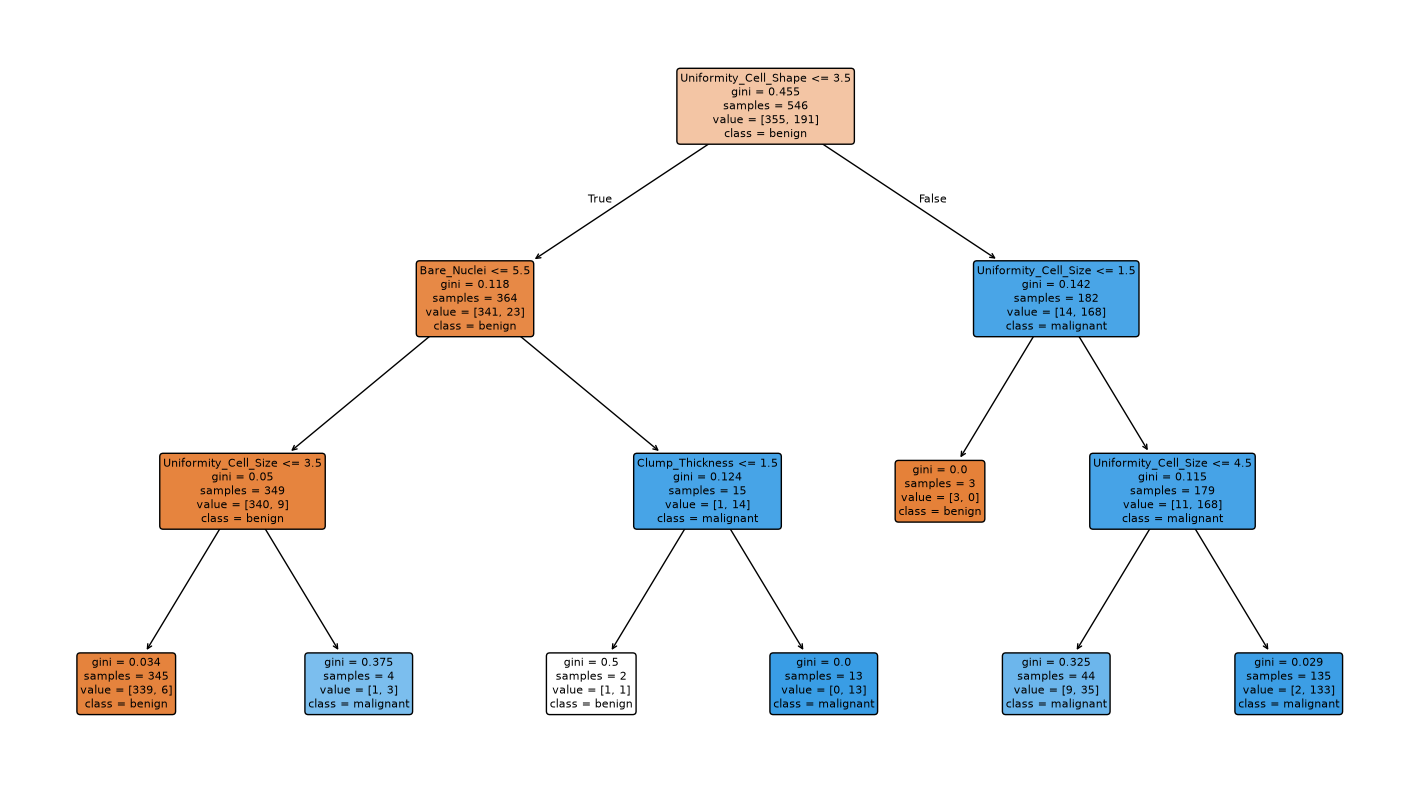

In [14]:
# Step 7: Visualize the Decision Tree
plt.figure(figsize=(18, 10))
plot_tree(
    model,
    feature_names=X.columns,
    class_names=["benign", "malignant"],
    filled=True,
    rounded=True,
    fontsize=8
)

In [19]:
print("Model:", model)
print("Number of tree nodes:", model.tree_.node_count)
print("Features:", X.shape)

Model: DecisionTreeClassifier(max_depth=3, random_state=42)
Number of tree nodes: 13
Features: (683, 9)


In [20]:
%matplotlib inline
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

In [23]:
print("Tree depth:", model.get_depth())
print("Number of leaves:", model.get_n_leaves())
print("Matplotlib backend:", plt.get_backend())

Tree depth: 3
Number of leaves: 7
Matplotlib backend: inline


In [24]:

# Logistic Regression Classifier

# Step 1: Import the required libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [25]:
# Step 2: Load the real-world dataset
columns = [
    "Sample_code_number", "Clump_Thickness",
    "Uniformity_Cell_Size", "Uniformity_Cell_Shape",
    "Marginal_Adhesion", "Single_Epithelial_Cell_Size",
    "Bare_Nuclei", "Bland_Chromatin",
    "Normal_Nucleoli", "Mitoses", "Class"
]

In [26]:
data = pd.read_csv(
    "breast-cancer-wisconsin.data",
    header=None,
    names=columns,
    na_values="?"
)

In [27]:
# Remove rows containing missing values (NaN)
data = data.dropna()

In [28]:
# Separate input features by removing the sample ID and target column
X = data.drop(columns=["Sample_code_number", "Class"])

In [29]:
# Convert the diagnosis labels into numerical values (2 -> 0, 4 -> 1)
y = data["Class"].map({2: 0, 4: 1})

In [30]:
# Display the number of rows and features in the dataset
print("Dataset shape:", X.shape)

Dataset shape: (683, 9)


In [31]:
# Display the names of the target classes
print("Target classes:", ["benign", "malignant"])

Target classes: ['benign', 'malignant']


In [32]:
# Split the dataset into 80% training data and 20% testing data
# stratify=y maintains the class proportions in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [33]:
# Standardize the features so they have comparable scales
scaler = StandardScaler()


In [34]:
# Learn scaling parameters from the training data and transform it
X_train = scaler.fit_transform(X_train)

In [35]:

# Apply the same scaling parameters to the testing data
X_test = scaler.transform(X_test)

In [36]:
# Create the Logistic Regression classifier
# max_iter=1000 allows more iterations for the model to converge
model = LogisticRegression(max_iter=1000, random_state=42)

In [37]:
# Train the model using the training dataset
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [38]:
# Predict the classes of the testing dataset
y_pred = model.predict(X_test)

In [39]:
# Calculate the proportion of correct predictions
print("\nAccuracy:", accuracy_score(y_test, y_pred))


Accuracy: 0.9635036496350365


In [40]:
# Display correct and incorrect predictions for each class
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Confusion Matrix:
[[85  4]
 [ 1 47]]


In [41]:
# Display precision, recall, F1-score, and support for each class
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, target_names=["benign", "malignant"]
))


Classification Report:
              precision    recall  f1-score   support

      benign       0.99      0.96      0.97        89
   malignant       0.92      0.98      0.95        48

    accuracy                           0.96       137
   macro avg       0.95      0.97      0.96       137
weighted avg       0.96      0.96      0.96       137



In [42]:
# Calculate the confusion matrix for visualization
cm = confusion_matrix(y_test, y_pred)


In [43]:
# Create a figure to display the confusion matrix
plt.figure(figsize=(6, 4))

<Figure size 600x400 with 0 Axes>

<Figure size 600x400 with 0 Axes>

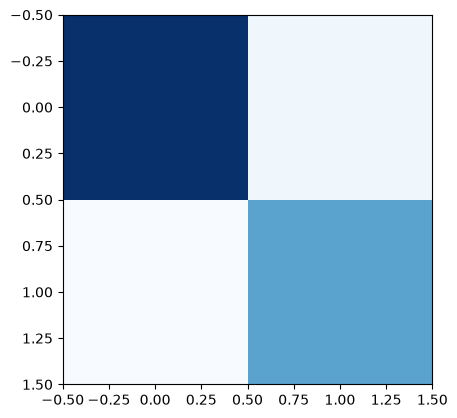

In [44]:
# Display the confusion matrix as a color-coded image
plt.imshow(cm, cmap="Blues")

Text(0, 0.5, 'Actual Class')

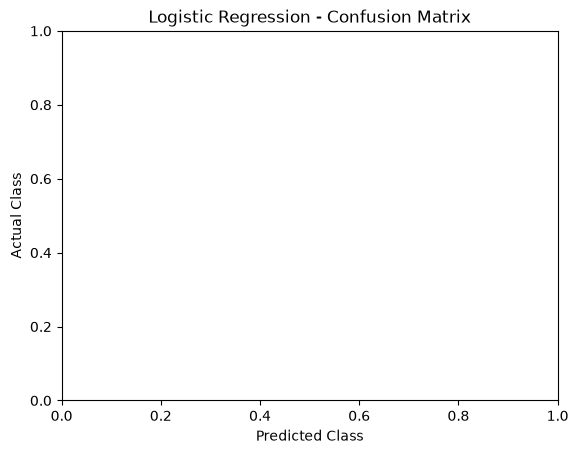

In [45]:
# Add a title and axis labels
plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

([<matplotlib.axis.YTick at 0x265a0857320>,
 [Text(0, 0, 'benign'), Text(0, 1, 'malignant')])

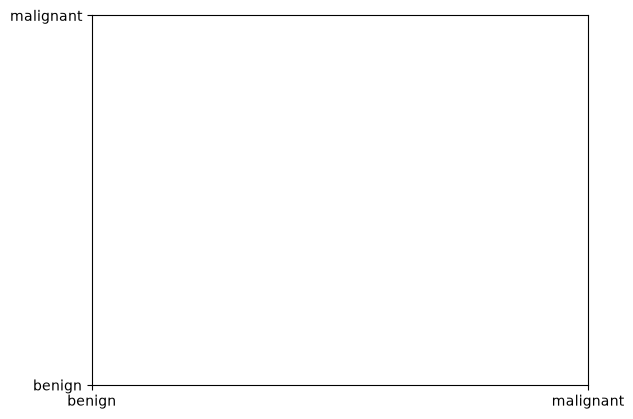

In [47]:
# Label the axes with the class names
plt.xticks([0, 1], ["benign", "malignant"])
plt.yticks([0, 1], ["benign", "malignant"])

In [49]:
# Adjust spacing to prevent labels from being cut off
plt.tight_layout()

# Display the final graph
plt.show()

<Figure size 640x480 with 0 Axes>

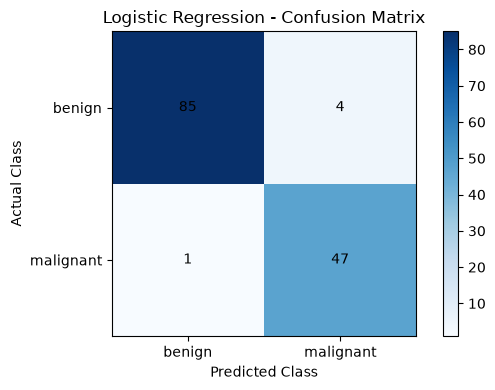

In [50]:

# Step 7: Visualize the Confusion Matrix

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Create a figure and axis
fig, ax = plt.subplots(figsize=(6, 4))

# Display the confusion matrix as a color-coded image
im = ax.imshow(cm, cmap="Blues")

# Add a title and axis labels
ax.set_title("Logistic Regression - Confusion Matrix")
ax.set_xlabel("Predicted Class")
ax.set_ylabel("Actual Class")

# Label the axes with the class names
ax.set_xticks([0, 1])
ax.set_xticklabels(["benign", "malignant"])
ax.set_yticks([0, 1])
ax.set_yticklabels(["benign", "malignant"])

# Display the color scale using the image
fig.colorbar(im, ax=ax)

# Display the values inside the confusion matrix
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center")

# Adjust spacing
plt.tight_layout()

# Display the final graph
plt.show()


Accuracy: 0.9562043795620438

Confusion Matrix:
[[85  4]
 [ 2 46]]

Classification Report:
              precision    recall  f1-score   support

      Benign       0.98      0.96      0.97        89
   Malignant       0.92      0.96      0.94        48

    accuracy                           0.96       137
   macro avg       0.95      0.96      0.95       137
weighted avg       0.96      0.96      0.96       137



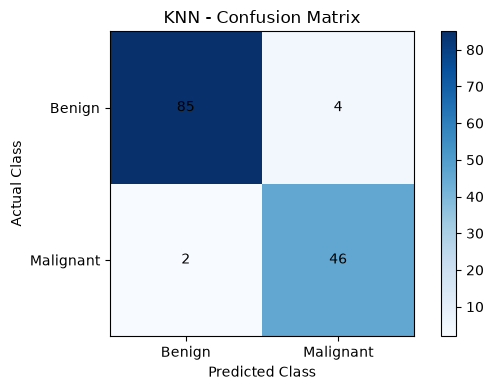

In [51]:

# Experiment: K-Nearest Neighbors (KNN) Classification

# Import pandas to load and handle the dataset
import pandas as pd

# Import matplotlib to visualize the results
import matplotlib.pyplot as plt

# Import train_test_split to divide data into training and testing sets
from sklearn.model_selection import train_test_split

# Import StandardScaler to scale the feature values
from sklearn.preprocessing import StandardScaler

# Import KNeighborsClassifier to build the KNN model
from sklearn.neighbors import KNeighborsClassifier

# Import evaluation metrics to measure model performance
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Define column names for the dataset
columns = [
    "Sample_code_number", "Clump_Thickness",
    "Uniformity_Cell_Size", "Uniformity_Cell_Shape",
    "Marginal_Adhesion", "Single_Epithelial_Cell_Size",
    "Bare_Nuclei", "Bland_Chromatin",
    "Normal_Nucleoli", "Mitoses", "Class"
]

# Load the dataset and treat '?' as missing data
data = pd.read_csv(
    "breast-cancer-wisconsin.data",
    header=None,
    names=columns,
    na_values="?"
)

# Remove rows containing missing values
data = data.dropna()

# Select the nine features for prediction
X = data.drop(columns=["Sample_code_number", "Class"])

# Convert the class labels: 2 = benign (0), 4 = malignant (1)
y = data["Class"].map({2: 0, 4: 1})

# Split the data into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale the features because KNN depends on distances
scaler = StandardScaler()

# Learn scaling values from the training data
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaling to the test data
X_test_scaled = scaler.transform(X_test)

# Create a KNN classifier using the five nearest neighbors
model = KNeighborsClassifier(n_neighbors=5)

# Train the model using the scaled training data
model.fit(X_train_scaled, y_train)

# Predict the classes of the test data
y_pred = model.predict(X_test_scaled)

# Calculate and display the model accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

# Display the confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(cm)

# Display precision, recall, and F1-score
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, target_names=["Benign", "Malignant"]
))

# Create a figure for the confusion matrix visualization
fig, ax = plt.subplots(figsize=(6, 4))

# Display the confusion matrix as a colored image
im = ax.imshow(cm, cmap="Blues")

# Add the graph title and axis labels
ax.set_title("KNN - Confusion Matrix")
ax.set_xlabel("Predicted Class")
ax.set_ylabel("Actual Class")

# Label the horizontal axis
ax.set_xticks([0, 1])
ax.set_xticklabels(["Benign", "Malignant"])

# Label the vertical axis
ax.set_yticks([0, 1])
ax.set_yticklabels(["Benign", "Malignant"])

# Add a color bar to indicate the values
fig.colorbar(im, ax=ax)

# Write the confusion matrix values inside the graph
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center")

# Adjust the graph layout
plt.tight_layout()

# Display the graph
plt.show()


Accuracy: 0.9635036496350365

Confusion Matrix:
[[85  4]
 [ 1 47]]

Classification Report:
              precision    recall  f1-score   support

      Benign       0.99      0.96      0.97        89
   Malignant       0.92      0.98      0.95        48

    accuracy                           0.96       137
   macro avg       0.95      0.97      0.96       137
weighted avg       0.96      0.96      0.96       137



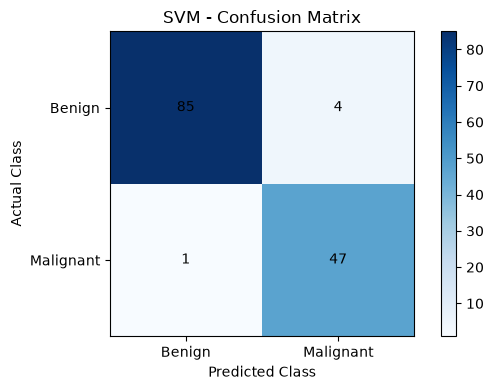

In [52]:

# Experiment: Support Vector Machine (SVM) Classification

# Import pandas to load and handle the dataset
import pandas as pd

# Import matplotlib to visualize the results
import matplotlib.pyplot as plt

# Import train_test_split to divide the dataset
from sklearn.model_selection import train_test_split

# Import StandardScaler to scale the features
from sklearn.preprocessing import StandardScaler

# Import SVC to create the SVM classifier
from sklearn.svm import SVC

# Import metrics to evaluate the model
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Define the column names of the dataset
columns = [
    "Sample_code_number", "Clump_Thickness",
    "Uniformity_Cell_Size", "Uniformity_Cell_Shape",
    "Marginal_Adhesion", "Single_Epithelial_Cell_Size",
    "Bare_Nuclei", "Bland_Chromatin",
    "Normal_Nucleoli", "Mitoses", "Class"
]

# Load the dataset and treat '?' as missing data
data = pd.read_csv(
    "breast-cancer-wisconsin.data",
    header=None,
    names=columns,
    na_values="?"
)

# Remove rows containing missing values
data = data.dropna()

# Select the nine input features
X = data.drop(columns=["Sample_code_number", "Class"])

# Convert class 2 to benign (0) and class 4 to malignant (1)
y = data["Class"].map({2: 0, 4: 1})

# Split the dataset into 80% training and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Create a scaler to normalize feature values
scaler = StandardScaler()

# Fit the scaler on training data and scale it
X_train_scaled = scaler.fit_transform(X_train)

# Scale the testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

# Create an SVM model with a radial basis function kernel
model = SVC(kernel="rbf")

# Train the model using the scaled training data
model.fit(X_train_scaled, y_train)

# Predict the classes of the testing data
y_pred = model.predict(X_test_scaled)

# Calculate and display accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

# Calculate and display the confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(cm)

# Display precision, recall, and F1-score
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, target_names=["Benign", "Malignant"]
))

# Create a figure for the confusion matrix
fig, ax = plt.subplots(figsize=(6, 4))

# Display the confusion matrix as a colored image
im = ax.imshow(cm, cmap="Blues")

# Add the graph title and axis labels
ax.set_title("SVM - Confusion Matrix")
ax.set_xlabel("Predicted Class")
ax.set_ylabel("Actual Class")

# Label the predicted classes
ax.set_xticks([0, 1])
ax.set_xticklabels(["Benign", "Malignant"])

# Label the actual classes
ax.set_yticks([0, 1])
ax.set_yticklabels(["Benign", "Malignant"])

# Add a color bar to the graph
fig.colorbar(im, ax=ax)

# Display the values inside each cell
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center")

# Adjust spacing in the graph
plt.tight_layout()

# Display the graph
plt.show()


Accuracy: 0.9562043795620438

Confusion Matrix:
[[85  4]
 [ 2 46]]

Classification Report:
              precision    recall  f1-score   support

      Benign       0.98      0.96      0.97        89
   Malignant       0.92      0.96      0.94        48

    accuracy                           0.96       137
   macro avg       0.95      0.96      0.95       137
weighted avg       0.96      0.96      0.96       137



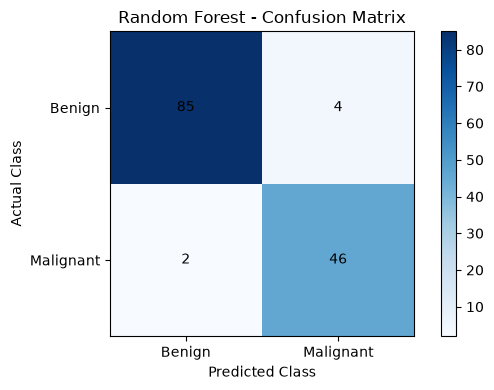

In [53]:

# Experiment: Random Forest Classification

# Import pandas to load the dataset
import pandas as pd

# Import matplotlib to visualize the confusion matrix
import matplotlib.pyplot as plt

# Import train_test_split to divide the dataset
from sklearn.model_selection import train_test_split

# Import RandomForestClassifier to build the model
from sklearn.ensemble import RandomForestClassifier

# Import metrics to evaluate the model
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Define the column names of the dataset
columns = [
    "Sample_code_number", "Clump_Thickness",
    "Uniformity_Cell_Size", "Uniformity_Cell_Shape",
    "Marginal_Adhesion", "Single_Epithelial_Cell_Size",
    "Bare_Nuclei", "Bland_Chromatin",
    "Normal_Nucleoli", "Mitoses", "Class"
]

# Load the dataset and treat '?' as missing data
data = pd.read_csv(
    "breast-cancer-wisconsin.data",
    header=None,
    names=columns,
    na_values="?"
)

# Remove rows containing missing values
data = data.dropna()

# Select the nine input features
X = data.drop(columns=["Sample_code_number", "Class"])

# Convert class 2 to benign (0) and class 4 to malignant (1)
y = data["Class"].map({2: 0, 4: 1})

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Create a Random Forest model with 100 decision trees
model = RandomForestClassifier(
    n_estimators=100, random_state=42
)

# Train the model using the training data
model.fit(X_train, y_train)

# Predict the classes of the testing data
y_pred = model.predict(X_test)

# Calculate and display model accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

# Calculate and display the confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(cm)

# Display precision, recall, and F1-score
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, target_names=["Benign", "Malignant"]
))

# Create a figure for the confusion matrix
fig, ax = plt.subplots(figsize=(6, 4))

# Display the confusion matrix as a colored image
im = ax.imshow(cm, cmap="Blues")

# Add the graph title and axis labels
ax.set_title("Random Forest - Confusion Matrix")
ax.set_xlabel("Predicted Class")
ax.set_ylabel("Actual Class")

# Label the predicted classes
ax.set_xticks([0, 1])
ax.set_xticklabels(["Benign", "Malignant"])

# Label the actual classes
ax.set_yticks([0, 1])
ax.set_yticklabels(["Benign", "Malignant"])

# Add a color bar
fig.colorbar(im, ax=ax)

# Display values inside each cell
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center")

# Adjust the graph layout
plt.tight_layout()

# Display the graph
plt.show()


Accuracy: 0.9635036496350365

Confusion Matrix:
[[85  4]
 [ 1 47]]

Classification Report:
              precision    recall  f1-score   support

      Benign       0.99      0.96      0.97        89
   Malignant       0.92      0.98      0.95        48

    accuracy                           0.96       137
   macro avg       0.95      0.97      0.96       137
weighted avg       0.96      0.96      0.96       137



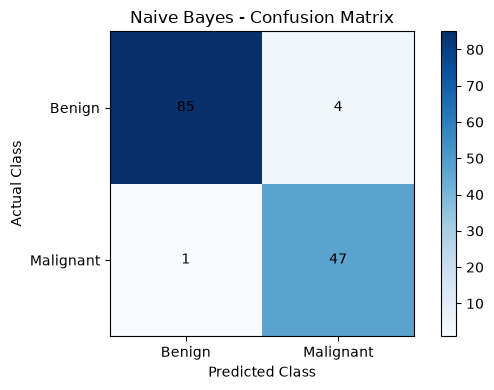

In [54]:

# Experiment: Naive Bayes Classification

# Import pandas to load the dataset
import pandas as pd

# Import matplotlib to visualize the results
import matplotlib.pyplot as plt

# Import train_test_split to divide the dataset
from sklearn.model_selection import train_test_split

# Import GaussianNB to create the Naive Bayes model
from sklearn.naive_bayes import GaussianNB

# Import metrics to evaluate model performance
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Define the column names of the dataset
columns = [
    "Sample_code_number", "Clump_Thickness",
    "Uniformity_Cell_Size", "Uniformity_Cell_Shape",
    "Marginal_Adhesion", "Single_Epithelial_Cell_Size",
    "Bare_Nuclei", "Bland_Chromatin",
    "Normal_Nucleoli", "Mitoses", "Class"
]

# Load the dataset and treat '?' as missing data
data = pd.read_csv(
    "breast-cancer-wisconsin.data",
    header=None,
    names=columns,
    na_values="?"
)

# Remove rows containing missing values
data = data.dropna()

# Select the nine input features
X = data.drop(columns=["Sample_code_number", "Class"])

# Convert class 2 to benign (0) and class 4 to malignant (1)
y = data["Class"].map({2: 0, 4: 1})

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Create the Gaussian Naive Bayes model
model = GaussianNB()

# Train the model using the training data
model.fit(X_train, y_train)

# Predict the classes of the testing data
y_pred = model.predict(X_test)

# Calculate and display model accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

# Calculate and display the confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(cm)

# Display precision, recall, and F1-score
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, target_names=["Benign", "Malignant"]
))

# Create a figure for the confusion matrix
fig, ax = plt.subplots(figsize=(6, 4))

# Display the confusion matrix as a colored image
im = ax.imshow(cm, cmap="Blues")

# Add the graph title and axis labels
ax.set_title("Naive Bayes - Confusion Matrix")
ax.set_xlabel("Predicted Class")
ax.set_ylabel("Actual Class")

# Label the predicted classes
ax.set_xticks([0, 1])
ax.set_xticklabels(["Benign", "Malignant"])

# Label the actual classes
ax.set_yticks([0, 1])
ax.set_yticklabels(["Benign", "Malignant"])

# Add a color bar
fig.colorbar(im, ax=ax)

# Display the values inside each cell
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center")

# Adjust the graph layout
plt.tight_layout()

# Display the graph
plt.show()
